1.3 Edge（边）
Edge定义节点的执行顺序。LangGraph提供两种Edge：
边类型                                  方法                                                说明
普通边（Normal Edge）           add_edge(node_a, node_b)                            固定流向：A执行完一定到B
条件边（Conditional Edge）      add_conditional_edges(node_a, router, mapping)      router的返回值决定下一节点

node_a is running, nodes: []
node_b is running, nodes: ['a']
node_c is running, nodes: ['a']
node_d is running, nodes: ['a', 'b', 'c']
{'nodes': ['a', 'b', 'c', 'd']}


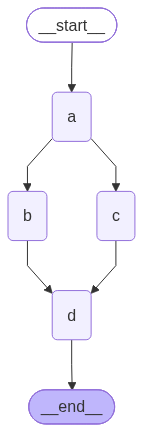

In [2]:
#包装并行edge

from operator import add
from typing import Annotated, TypedDict
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from IPython.display import Image, display

# =================1. 定义State数据结构和Reducer=================
class ParallelState(TypedDict):
    nodes: Annotated[list[str], add]

# =================2. Node: 定义处理逻辑=================
def node_a(state: ParallelState):
    print(f"node_a is running, nodes: {state['nodes']}")
    return {"nodes": ["a"]}


def node_b(state: ParallelState):
    print(f"node_b is running, nodes: {state['nodes']}")
    return {"nodes": ["b"]}

def node_c(state: ParallelState):
    print(f"node_c is running, nodes: {state['nodes']}")
    return {"nodes": ["c"]}

def node_d(state: ParallelState):
    print(f"node_d is running, nodes: {state['nodes']}")
    return {"nodes": ["d"]}

# ===================3. 创建Graph===================
builder = StateGraph(ParallelState)
builder.add_node("a", node_a)
builder.add_node("b", node_b)
builder.add_node("c", node_c)
builder.add_node("d", node_d)
builder.add_edge(START, "a")         # start -> a
builder.add_edge("a", "b")           # a -> b
builder.add_edge("a", "c")           # a -> c
builder.add_edge("b", "d")           # b -> d
builder.add_edge("c", "d")           # c -> d
builder.add_edge("d", END)           # d -> end
parallel_graph = builder.compile()

# =================4.调用Graph，传入默认State值=================
result = parallel_graph.invoke({})
print(result)

display(Image(parallel_graph.get_graph(xray=True).draw_mermaid_png()))

59
{'score': 59, 'result': '不通过'}


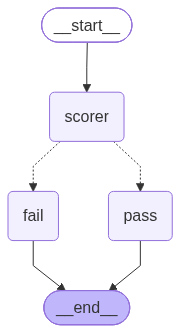

In [7]:
#条件边
# 我们实现一个成绩判定的Graph，用户输入一个分数，我们根据分数判断走哪个节点：
# - 大于60，走成功节点
# - 小于60，走失败节点

from typing import TypedDict, Literal
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from IPython.display import Image, display

# =================1. 定义State数据结构================
class GradeState(TypedDict):
    score: int
    result: str

# =================2. Node: 定义处理逻辑=================
def scorer(state: GradeState):
    score = int(input("请输入分数:"))
    print(score)
    return {"score": score}  # 模拟评分

def pass_node(state: GradeState):
    return {"result": "通过"}
def fail_node(state: GradeState):
    return {"result": "不通过"}

# =================3. 定义路由节点，决定下个Node=================
def router(state: GradeState) -> Literal["pass", "fail"]:
    if state["score"] >= 60:
        return "pass"
    else:
        return "fail"


# =================4. 定义Graph=================
graph = StateGraph(GradeState)
graph.add_node("scorer", scorer)
graph.add_node("pass", pass_node)
graph.add_node("fail", fail_node)
graph.add_edge(START, "scorer")
graph.add_conditional_edges("scorer", router)
graph.add_edge("pass", END)
graph.add_edge("fail", END)
conditional_graph = graph.compile()

res = conditional_graph.invoke({})
print(res)

display(Image(conditional_graph.get_graph(xray=True).draw_mermaid_png()))


66
{'score': 66, 'result': '通过'}


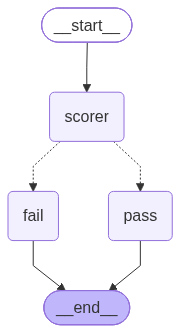

: 

In [ ]:
#如果不想编写Conditional Edge，也可以在Node中直接返回下个节点信息。
# 但是，由于Node必须返回对State的更新，而没有条件边就需要返回下个节点的名字。函数返回值只能有一个。
# 所以LangGraph就提供了Command API，用Command来指定下个节点以及要更新的字段。

from typing import TypedDict, Literal
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from IPython.display import Image, display
from langgraph.types import Command

# =================1. 定义State数据结构================
class GradeState(TypedDict):
    score: int
    result: str

# =================2. Node: 定义处理逻辑=================
def scorer(state: GradeState) -> Command[Literal["pass", "fail"]]:
                    # 定义返回值为Command对象，指定下个节点为pass或fail
    score = int(input("请输入分数:"))
    print(score)

    goto = "fail"
    if score >= 60:
        goto = "pass"
    
    # 返回Command对象，指定要更新的字段和下个节点
    # update: 要更新的state
    # goto: 下个节点
    return Command(
        update = {"score": score},
        goto=goto
    )

def pass_node(state: GradeState):
    return {"result": "通过"}
def fail_node(state: GradeState):
    return {"result": "不通过"}


# =================4. 定义Graph=================
graph = StateGraph(GradeState)
graph.add_node("scorer", scorer)
graph.add_node("pass", pass_node)
graph.add_node("fail", fail_node)
graph.add_edge(START, "scorer")
graph.add_edge("pass", END)
graph.add_edge("fail", END)
conditional_graph = graph.compile()

res = conditional_graph.invoke({})
print(res)

display(Image(conditional_graph.get_graph(xray=True).draw_mermaid_png()))
